---
title: 3.2.b Amenaza — Sequía y seguridad hídrica
short_title: b. Amenaza
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/sincelejo/blob/main/book/03_analisis/32_sequia/b_amenaza.ipynb)

**Reproducible sin red en el checkout.** La fuente preservada y sus limitaciones se describen en el capítulo 2.3.


In [1]:
from pathlib import Path
import sys, subprocess
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'src/sincelejo/analisis.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/sincelejo')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/mromerot/sincelejo.git',str(ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(ROOT)+'[libro]'],check=True)
sys.path.insert(0,str(ROOT/'src'))
from sincelejo.nb import *  # clima, anual, evidencia, ROOT, pd, plt, json, display, funciones

## Método

CDD describe rachas secas; Z-P3 compara acumulados trimestrales con la climatología del mes de cierre. Se propone contrastar después con SPI/SPEI, humedad de suelo y piezometría. La respuesta del acuífero puede presentar rezagos y depender de recarga fuera del punto climático.

,p_total,cdd
anio,,
1991,1187.89,34
1992,1195.38,35
1993,1886.88,16
1994,1746.93,13
1995,1480.75,29
1996,1345.99,18
1997,996.62,52
1998,1501.95,36
1999,1687.21,15


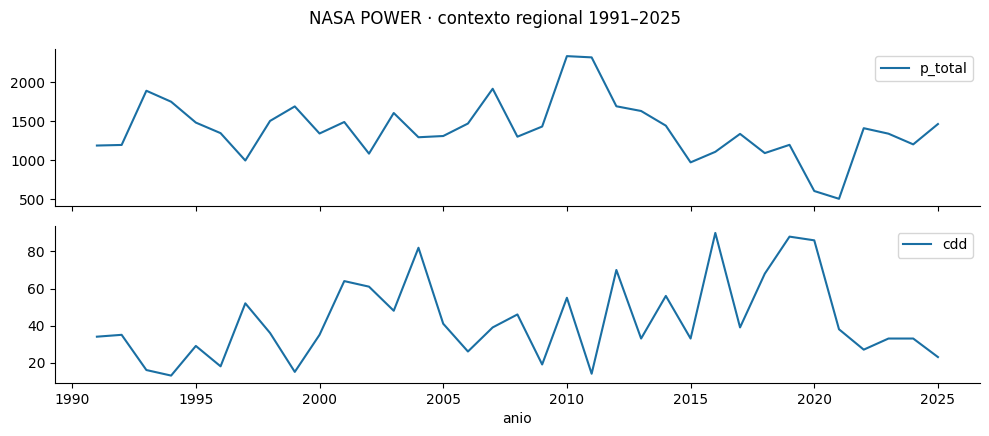

In [2]:
columnas = ['p_total', 'cdd']
display(anual[columnas].round(2))
anual[columnas].plot(subplots=True,figsize=(10,4.4),color='#1a6fa3',legend=True)
plt.suptitle('NASA POWER · contexto regional 1991–2025'); plt.tight_layout(); plt.show()

,p3_mm,z_p3
fecha,,
2021-07-01,64.78,-3.28
2021-06-01,45.37,-2.72
2021-08-01,119.65,-2.49
2021-09-01,167.34,-2.43
2020-11-01,146.63,-2.21
2021-05-01,47.14,-2.14
1997-07-01,241.58,-2.09
2020-12-01,71.50,-2.00
2020-06-01,157.52,-1.93


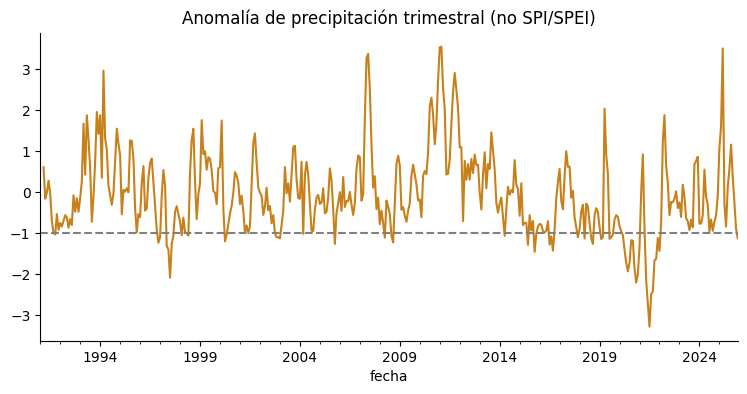

In [3]:
z = deficit_trimestral(clima)
display(z.nsmallest(10,'z_p3').round(2))
z.z_p3.plot(color='#c8811a',title='Anomalía de precipitación trimestral (no SPI/SPEI)'); plt.axhline(-1,color='gray',ls='--'); plt.show()

## Interpretación

Se publican rachas y anomalías meteorológicas. La seguridad hídrica requiere balances y series operativas adicionales: no se infiere un agotamiento del acuífero ni un porcentaje de hogares desabastecidos.

Para el vínculo con exposición y vulnerabilidad continúe con [riesgo](c_riesgo.ipynb).